# 1. Train a quantum PINN and test it

This notebook trains a counterdiabatic PINN for the two-qubit H$_2$ Hamiltonian at 1.0 Å on a CPU in a few seconds, then checks what it learned:

1. the loss terms during training;
2. the schedule $\lambda(t)$ and the counterdiabatic term, against the exact gauge potential;
3. state preparation: propagating the Schrödinger equation with and without the learned term;
4. saving and reloading the model.

The run is much shorter than in the article (3000 Adam updates on 256 points instead of 500000 on 2048, with a larger learning rate), but it already learns a useful counterdiabatic term.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from quantum_pinn import RunConfig, evaluate, load_checkpoint, load_hamiltonians, train
from quantum_pinn.analysis import complete, counterdiabatic_coefficients, dynamics
from quantum_pinn.physics import pauli_strings

torch.set_num_threads(1)  # deterministic and comparable timings

## The problem

$H_{\mathrm{initial}}$ is the diagonal (Hartree–Fock) part of the molecular Hamiltonian $H_{\mathrm{final}}$. The protocol must carry the ground state of the first into the ground state of the second in a total time of 1 ($\hbar=1$, energies in hartree).

In [2]:
h_initial, h_final = load_hamiltonians("h2", 1.0)
np.set_printoptions(precision=4, suppress=True)
print("H_initial =\n", h_initial.real)
print("H_final =\n", h_final.real)
print("ground energies:", np.linalg.eigvalsh(h_initial)[0], "->", np.linalg.eigvalsh(h_final)[0])

H_initial =
 [[-0.5491  0.      0.      0.    ]
 [ 0.     -1.0661  0.      0.    ]
 [ 0.      0.      0.004   0.    ]
 [ 0.      0.      0.     -0.5491]]
H_final =
 [[-0.5491  0.      0.      0.1968]
 [ 0.     -1.0661  0.1968  0.    ]
 [ 0.      0.1968  0.004   0.    ]
 [ 0.1968  0.      0.     -0.5491]]
ground energies: -1.0661087036132812 -> -1.1011503802844667


## Train

`RunConfig` defaults follow the article (6 hidden layers of 30 tanh units, loss weights of eq. 16). We shorten the run and raise the learning rate. `train` writes `config.json`, `history.npz` (every loss term at every update) and `model.pt` to a new directory.

In [3]:
config = RunConfig(system="h2", distance=1.0, collocation=256, steps=3000, learning_rate=1e-3)
output = Path(tempfile.mkdtemp()) / "h2-short"
model, summary = train(config, output)
print(f"{config.steps} updates in {summary['seconds']:.1f} s, final loss {summary['final_loss']:.3f}")
print(sorted(p.name for p in output.iterdir()))

3000 updates in 4.6 s, final loss 1.311
['config.json', 'history.npz', 'model.pt']


The boundary, least-action and Pauli terms fall by three to six orders of magnitude. The brief spikes near the end come from Adam overshooting at this large learning rate. The $\dot\lambda^2$ penalty grows from almost zero: the initial network has a nearly constant $\lambda$, and the boundary conditions force it to rise from 0 to 1.

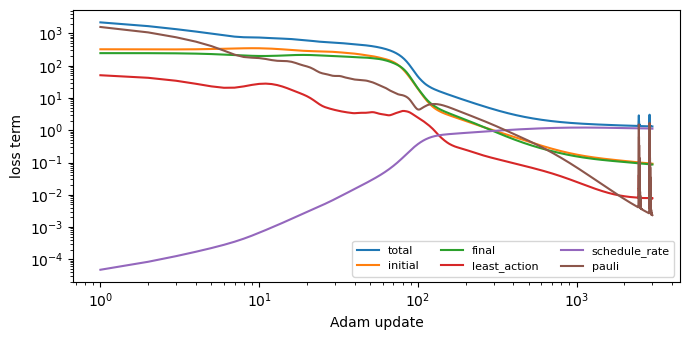

In [4]:
history = np.load(output / "history.npz")
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in ("total", "initial", "final", "least_action", "schedule_rate", "pauli"):
    ax.loglog(np.arange(1, config.steps + 1), history[name], label=name)
ax.set_xlabel("Adam update")
ax.set_ylabel("loss term")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()

## What the network learned

`evaluate` returns NumPy arrays on a uniform grid; `complete` adds the Hamiltonians, the counterdiabatic term $H_{\mathrm{CD}}=\dot\lambda A_{\mathrm{CD}}$, and the exact gauge potential for the same schedule. For this Hamiltonian the exact potential contains only the $XY$ and $YX$ Pauli strings.

After this short run $\lambda(t)$ is still a sigmoid, the early training stage shown in Figure 3 of the article. The linear schedule $\lambda=t$, which minimises the $\dot\lambda^2$ penalty, appears only after tens of thousands of updates. The learned coefficients already follow the exact potential for this schedule (dashed), and $H_{\mathrm{CD}}$ is small at both ends because $\dot\lambda$ is.

largest |H_CD| element at t=0, t=1, and overall: 0.005291803 0.0051136133 0.6222252


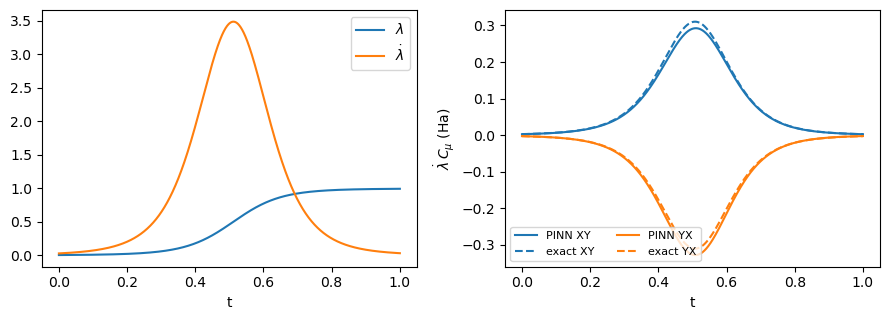

In [5]:
data = complete(evaluate(model, "h2", 1.0, points=2001), "h2", 1.0)
coefficients = counterdiabatic_coefficients(data)
names = pauli_strings(2)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.3))
left.plot(data["time"], data["schedule"], label=r"$\lambda$")
left.plot(data["time"], data["schedule_rate"], label=r"$\dot\lambda$")
left.set_xlabel("t")
left.legend()
for name in ("XY", "YX"):
    i = names.index(name)
    (line,) = right.plot(data["time"], coefficients["learned"][:, i], label=f"PINN {name}")
    right.plot(data["time"], coefficients["exact"][:, i], "--", color=line.get_color(), label=f"exact {name}")
right.set_xlabel("t")
right.set_ylabel(r"$\dot\lambda\, C_\mu$ (Ha)")
right.legend(ncol=2, fontsize=8)
fig.tight_layout()

cd = data["counterdiabatic"]
print("largest |H_CD| element at t=0, t=1, and overall:", np.abs(cd[0]).max(), np.abs(cd[-1]).max(), np.abs(cd).max())

## Does it prepare the ground state?

`dynamics` propagates the ground state of $H_{\mathrm{initial}}$ under $H(t)=H_{\mathrm{AD}}+\dot\lambda A_{\mathrm{CD}}$ and, for comparison, under $H_{\mathrm{AD}}$ alone with the same schedule. It reports the population of the instantaneous ground state of $H_{\mathrm{AD}}(t)$.

 counterdiabatic: final ground population 0.99989, <H_final> = -1.101109 Ha (exact -1.101150)
       adiabatic: final ground population 0.97027, <H_final> = -1.066945 Ha (exact -1.101150)


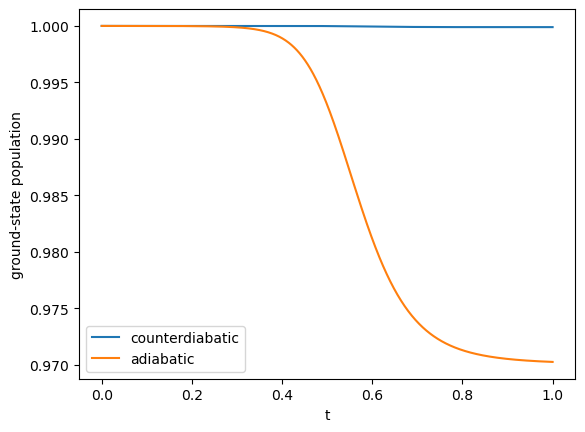

In [6]:
runs = dynamics(data, stride=2)
exact = np.linalg.eigvalsh(h_final)[0]
for name, run in runs.items():
    plt.plot(run["time"], run["ground_population"], label=name)
    print(f"{name:>16}: final ground population {run['ground_population'][-1]:.5f}, "
          f"<H_final> = {run['final_energy']:.6f} Ha (exact {exact:.6f})")
plt.xlabel("t")
plt.ylabel("ground-state population")
plt.legend();

## Save and reload

Checkpoints store the configuration with the weights, so the architecture is rebuilt automatically.

In [7]:
reloaded, loaded_config = load_checkpoint(output / "model.pt")
t = torch.linspace(0, 1, 5).reshape(-1, 1)
assert torch.equal(model.predict(t)["potential"], reloaded.predict(t)["potential"])
print(loaded_config)

RunConfig(system='h2', distance=1.0, width=30, hidden_layers=6, collocation=256, steps=3000, learning_rate=0.001, weights='paper', seed=7, dtype='float32', device='cpu', snapshot_steps=())


## Next steps

* The article's full run takes about 1.7 h on a laptop CPU:
  `quantum-pinn train --experiment paper/h2-d1.0 --output datasets/runs/h2-paper`
* [Notebook 2](inference.ipynb) evaluates the models trained for the article.
* [Notebook 3](reproduce-results.ipynb) recomputes the article's results.